In [1]:
import pandas as pd
import numpy as np
import os
import zipfile
import urllib.request
from datetime import datetime

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
# Create data lake directories

folders = ['bronze', 'silver', 'gold']

for folder in folders:
    os.makedirs(folder, exist_ok=True)

print("Data Lake folders created successfully!")

# Display folder structure
for folder in folders:
    print(f"📁 {folder}/")

Data Lake folders created successfully!
📁 bronze/
📁 silver/
📁 gold/


In [5]:
zip_path = r"C:\Users\ADITYA SINGH\Downloads\book-crossings.zip"

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall('raw_data')

print("Dataset extracted successfully!")

print(os.listdir('raw_data'))

Dataset extracted successfully!
['BX-Book-Ratings.csv', 'BX-Books.csv', 'BX-Users.csv']


In [ ]:
books = pd.read_csv(
    r"C:\Users\ADITYA SINGH\Downloads\book-crossings\BX-Books.csv",
    sep=';',
    encoding='latin-1',
    engine='python',
    on_bad_lines='warn'
)

print("Books dataset loaded successfully!")
print("Shape:", books.shape)

In [11]:
file_path = r"C:\Users\ADITYA SINGH\Downloads\book-crossings\BX-Books.csv"

with open(file_path, 'r', encoding='latin-1') as file:
    for i in range(8):
        print(file.readline())

"ISBN";"Book-Title";"Book-Author";"Year-Of-Publication";"Publisher";"Image-URL-S";"Image-URL-M";"Image-URL-L"

"0195153448";"Classical Mythology";"Mark P. O. Morford";"2002";"Oxford University Press";"http://images.amazon.com/images/P/0195153448.01.THUMBZZZ.jpg";"http://images.amazon.com/images/P/0195153448.01.MZZZZZZZ.jpg";"http://images.amazon.com/images/P/0195153448.01.LZZZZZZZ.jpg"

"0002005018";"Clara Callan";"Richard Bruce Wright";"2001";"HarperFlamingo Canada";"http://images.amazon.com/images/P/0002005018.01.THUMBZZZ.jpg";"http://images.amazon.com/images/P/0002005018.01.MZZZZZZZ.jpg";"http://images.amazon.com/images/P/0002005018.01.LZZZZZZZ.jpg"

"0060973129";"Decision in Normandy";"Carlo D'Este";"1991";"HarperPerennial";"http://images.amazon.com/images/P/0060973129.01.THUMBZZZ.jpg";"http://images.amazon.com/images/P/0060973129.01.MZZZZZZZ.jpg";"http://images.amazon.com/images/P/0060973129.01.LZZZZZZZ.jpg"

"0374157065";"Flu: The Story of the Great Influenza Pandemic of 1918 and

In [13]:

import csv
import pandas as pd

file_path = r"C:\Users\ADITYA SINGH\Downloads\book-crossings\BX-Books.csv"

columns = [
    'ISBN',
    'Book-Title',
    'Book-Author',
    'Year-Of-Publication',
    'Publisher',
    'Image-URL-S',
    'Image-URL-M',
    'Image-URL-L'
]

repaired_rows = []
bad_rows = []

with open(file_path, 'r', encoding='latin-1', newline='') as file:
    reader = csv.reader(file, delimiter=';', quotechar='"')

    for line_no, row in enumerate(reader, start=1):

        if not row:
            continue

        if len(row) == 8:
            repaired_rows.append(row)

        elif len(row) > 8:
            # Preserve extra title/publisher fragments
            extra = len(row) - 8

            repaired_row = (
                row[:2]
                + [';'.join(row[2:3 + extra])]
                + row[3 + extra:]
            )

            if len(repaired_row) == 8:
                repaired_rows.append(repaired_row)
            else:
                bad_rows.append((line_no, row))

        else:
            bad_rows.append((line_no, row))

books = pd.DataFrame(repaired_rows, columns=columns)

print("Books loaded:", books.shape)
print("Unresolved rows:", len(bad_rows))


Books loaded: (271377, 8)
Unresolved rows: 3


In [14]:
import pandas as pd
import csv

# Load Users dataset
users = pd.read_csv(
    r"C:\Users\ADITYA SINGH\Downloads\book-crossings\BX-Users.csv",
    sep=';',
    encoding='latin-1',
    low_memory=False
)

# Load Ratings dataset
ratings = pd.read_csv(
    r"C:\Users\ADITYA SINGH\Downloads\book-crossings\BX-Book-Ratings.csv",
    sep=';',
    encoding='latin-1',
    low_memory=False
)

print("All datasets loaded successfully!")

# Check dataset dimensions
print("Users:", users.shape)
print("Books:", books.shape)
print("Ratings:", ratings.shape)

All datasets loaded successfully!
Users: (278858, 3)
Books: (271377, 8)
Ratings: (1149780, 3)


In [15]:
print("Unresolved records:", len(bad_rows))

for line_no, row in bad_rows:
    print(f"\nLine: {line_no}")
    print("Columns:", len(row))
    print(row)

Unresolved records: 3

Line: 209552
Columns: 7
['078946697X', 'DK Readers: Creating the X-Men, How It All Began (Level 4: Proficient Readers)\\";Michael Teitelbaum"', '2000', 'DK Publishing Inc', 'http://images.amazon.com/images/P/078946697X.01.THUMBZZZ.jpg', 'http://images.amazon.com/images/P/078946697X.01.MZZZZZZZ.jpg', 'http://images.amazon.com/images/P/078946697X.01.LZZZZZZZ.jpg']

Line: 220746
Columns: 7
['2070426769', 'Peuple du ciel, suivi de \'Les Bergers\\";Jean-Marie Gustave Le ClÃ?Â©zio"', '2003', 'Gallimard', 'http://images.amazon.com/images/P/2070426769.01.THUMBZZZ.jpg', 'http://images.amazon.com/images/P/2070426769.01.MZZZZZZZ.jpg', 'http://images.amazon.com/images/P/2070426769.01.LZZZZZZZ.jpg']

Line: 221693
Columns: 7
['0789466953', 'DK Readers: Creating the X-Men, How Comic Books Come to Life (Level 4: Proficient Readers)\\";James Buckley"', '2000', 'DK Publishing Inc', 'http://images.amazon.com/images/P/0789466953.01.THUMBZZZ.jpg', 'http://images.amazon.com/images/P/0

In [16]:
# Repair the three malformed records

for line_no, row in bad_rows:

    # Extract title and author from the combined field
    title_author = row[1]

    title, author = title_author.rsplit(';', 1)

    title = title.replace('\\"', '').strip()
    author = author.replace('"', '').strip()

    repaired_row = [
        row[0],          # ISBN
        title,           # Book-Title
        author,          # Book-Author
        row[2],          # Year-Of-Publication
        row[3],          # Publisher
        row[4],          # Image-URL-S
        row[5],          # Image-URL-M
        row[6]           # Image-URL-L
    ]

    # Add repaired record
    books.loc[len(books)] = repaired_row

print("Three records repaired successfully!")

print("Updated Books Shape:", books.shape)

Three records repaired successfully!
Updated Books Shape: (271380, 8)


In [17]:
print("FINAL DATASET VALIDATION")
print("------------------------")

print("Users:", users.shape)
print("Books:", books.shape)
print("Ratings:", ratings.shape)

print("\nBooks columns:")
print(books.columns.tolist())

print("\nCheck missing rows:")
print("Books records:", len(books))

FINAL DATASET VALIDATION
------------------------
Users: (278858, 3)
Books: (271380, 8)
Ratings: (1149780, 3)

Books columns:
['ISBN', 'Book-Title', 'Book-Author', 'Year-Of-Publication', 'Publisher', 'Image-URL-S', 'Image-URL-M', 'Image-URL-L']

Check missing rows:
Books records: 271380


In [18]:
import os

os.makedirs('bronze', exist_ok=True)

users.to_parquet('bronze/users.parquet', index=False)
books.to_parquet('bronze/books.parquet', index=False)
ratings.to_parquet('bronze/ratings.parquet', index=False)

print("Bronze Layer created successfully!")

Bronze Layer created successfully!


In [19]:
bronze_users = pd.read_parquet('bronze/users.parquet')
bronze_books = pd.read_parquet('bronze/books.parquet')
bronze_ratings = pd.read_parquet('bronze/ratings.parquet')

print("Users:", bronze_users.shape)
print("Books:", bronze_books.shape)
print("Ratings:", bronze_ratings.shape)

Users: (278858, 3)
Books: (271380, 8)
Ratings: (1149780, 3)


# **Exploratory Data Analysis (EDA)**

In [20]:
# Load Bronze datasets

users = pd.read_parquet('bronze/users.parquet')
books = pd.read_parquet('bronze/books.parquet')
ratings = pd.read_parquet('bronze/ratings.parquet')

print("Bronze datasets loaded successfully!")

Bronze datasets loaded successfully!


In [21]:
datasets = {
    'Users': users,
    'Books': books,
    'Ratings': ratings
}

for name, df in datasets.items():

    print(f"\n{'='*40}")
    print(f"{name} Dataset")
    print('='*40)

    print("Shape:", df.shape)

    print("\nData Types:")
    print(df.dtypes)

    print("\nMissing Values:")
    print(df.isnull().sum())


Users Dataset
Shape: (278858, 3)

Data Types:
User-ID       int64
Location        str
Age         float64
dtype: object

Missing Values:
User-ID          0
Location         0
Age         110762
dtype: int64

Books Dataset
Shape: (271380, 8)

Data Types:
ISBN                   str
Book-Title             str
Book-Author            str
Year-Of-Publication    str
Publisher              str
Image-URL-S            str
Image-URL-M            str
Image-URL-L            str
dtype: object

Missing Values:
ISBN                   0
Book-Title             0
Book-Author            0
Year-Of-Publication    0
Publisher              0
Image-URL-S            0
Image-URL-M            0
Image-URL-L            0
dtype: int64

Ratings Dataset
Shape: (1149780, 3)

Data Types:
User-ID        int64
ISBN             str
Book-Rating    int64
dtype: object

Missing Values:
User-ID        0
ISBN           0
Book-Rating    0
dtype: int64


In [22]:
display(users.head())
display(books.head())
display(ratings.head())

,User-ID,Location,Age
0,1,"nyc, new york, usa",NaN
1,2,"stockton, california, usa",18.0
2,3,"moscow, yukon territory, russia",NaN
3,4,"porto, v.n.gaia, portugal",17.0
4,5,"farnborough, hants, united kingdom",NaN


,ISBN,Book-Title,Book-Author,Year-Of-Publication,Publisher,Image-URL-S,Image-URL-M,Image-URL-L
0,ISBN,Book-Title,Book-Author,Year-Of-Publication,Publisher,Image-URL-S,Image-URL-M,Image-URL-L
1,0195153448,Classical Mythology,Mark P. O. Morford,2002,Oxford University Press,http://images.amazon.com/images/P/0195153448.0...,http://images.amazon.com/images/P/0195153448.0...,http://images.amazon.com/images/P/0195153448.0...
2,0002005018,Clara Callan,Richard Bruce Wright,2001,HarperFlamingo Canada,http://images.amazon.com/images/P/0002005018.0...,http://images.amazon.com/images/P/0002005018.0...,http://images.amazon.com/images/P/0002005018.0...
3,0060973129,Decision in Normandy,Carlo D'Este,1991,HarperPerennial,http://images.amazon.com/images/P/0060973129.0...,http://images.amazon.com/images/P/0060973129.0...,http://images.amazon.com/images/P/0060973129.0...
4,0374157065,Flu: The Story of the Great Influenza Pandemic...,Gina Bari Kolata,1999,Farrar Straus Giroux,http://images.amazon.com/images/P/0374157065.0...,http://images.amazon.com/images/P/0374157065.0...,http://images.amazon.com/images/P/0374157065.0...


,User-ID,ISBN,Book-Rating
0,276725,034545104X,0
1,276726,0155061224,5
2,276727,0446520802,0
3,276729,052165615X,3
4,276729,0521795028,6


Rating Distribution:
Book-Rating
0     716109
1       1770
2       2759
3       5996
4       8904
5      50974
6      36924
7      76457
8     103736
9      67541
10     78610
Name: count, dtype: int64


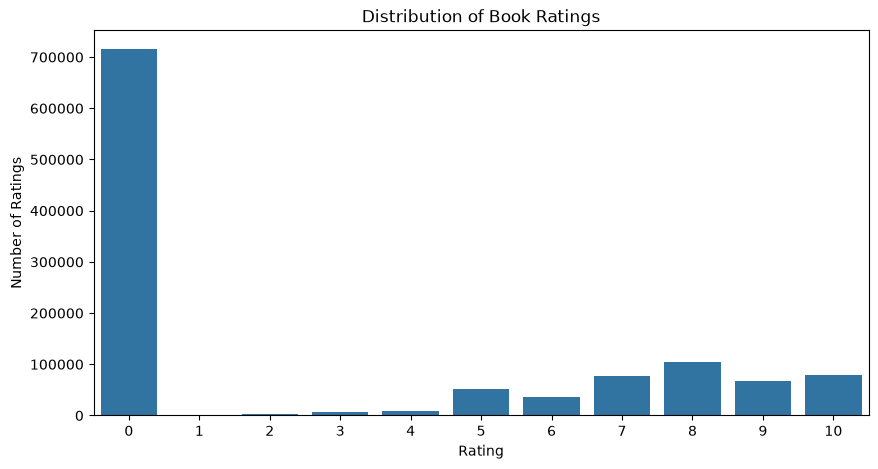

Zero ratings: 716109
Explicit ratings: 433671


In [23]:
import matplotlib.pyplot as plt
import seaborn as sns

rating_counts = ratings['Book-Rating'].value_counts().sort_index()

print("Rating Distribution:")
print(rating_counts)

plt.figure(figsize=(10, 5))
sns.barplot(x=rating_counts.index, y=rating_counts.values)

plt.title("Distribution of Book Ratings")
plt.xlabel("Rating")
plt.ylabel("Number of Ratings")
plt.show()

print("Zero ratings:", (ratings['Book-Rating'] == 0).sum())
print("Explicit ratings:", (ratings['Book-Rating'] != 0).sum())

User Age Statistics:
count    168096.000000
mean         34.751434
std          14.428097
min           0.000000
25%          24.000000
50%          32.000000
75%          44.000000
max         244.000000
Name: Age, dtype: float64


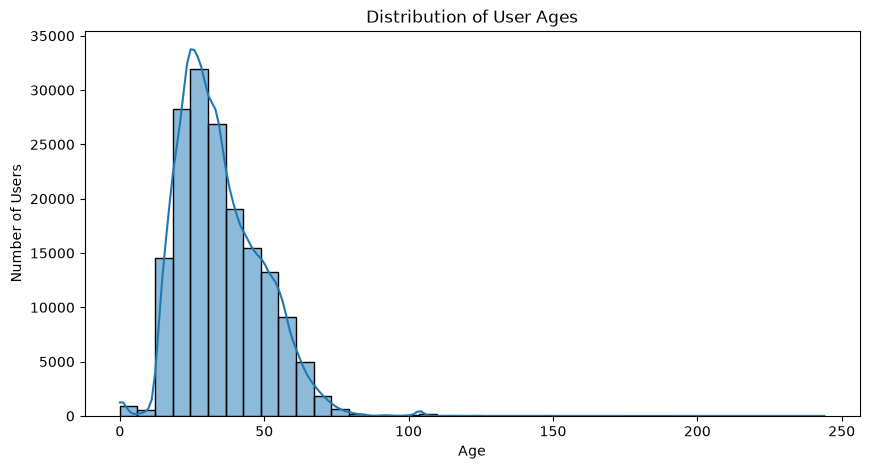

Missing Ages: 110762
Age below 5: 882
Age above 100: 366


In [24]:
print("User Age Statistics:")
print(users['Age'].describe())

plt.figure(figsize=(10, 5))
sns.histplot(users['Age'].dropna(), bins=40, kde=True)

plt.title("Distribution of User Ages")
plt.xlabel("Age")
plt.ylabel("Number of Users")
plt.show()

print("Missing Ages:", users['Age'].isnull().sum())
print("Age below 5:", (users['Age'] < 5).sum())
print("Age above 100:", (users['Age'] > 100).sum())

Publication Year Statistics:
count    271379.000000
mean       1959.756050
std         258.011363
min           0.000000
25%        1989.000000
50%        1995.000000
75%        2000.000000
max        2050.000000
Name: Year-Of-Publication, dtype: float64
Year 0: 4619
Future Years: 11


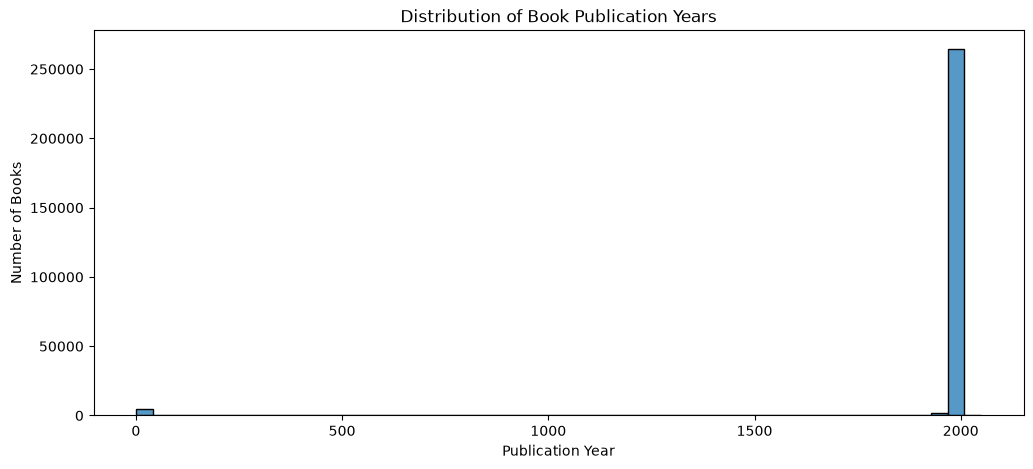

In [25]:
books['Year-Of-Publication'] = pd.to_numeric(
    books['Year-Of-Publication'],
    errors='coerce'
)

print("Publication Year Statistics:")
print(books['Year-Of-Publication'].describe())

print("Year 0:", (books['Year-Of-Publication'] == 0).sum())

print("Future Years:",
      (books['Year-Of-Publication'] > 2026).sum())

plt.figure(figsize=(12, 5))
sns.histplot(
    books['Year-Of-Publication'].dropna(),
    bins=50
)

plt.title("Distribution of Book Publication Years")
plt.xlabel("Publication Year")
plt.ylabel("Number of Books")
plt.show()

In [26]:
# Count ratings given by each user

user_rating_counts = ratings.groupby('User-ID')['ISBN'].count()

print("User Rating Statistics:")
print(user_rating_counts.describe())

print("\nUsers with only 1 rating:",
      (user_rating_counts == 1).sum())

print("Users with fewer than 10 ratings:",
      (user_rating_counts < 10).sum())

User Rating Statistics:
count    105283.000000
mean         10.920851
std          90.562825
min           1.000000
25%           1.000000
50%           1.000000
75%           4.000000
max       13602.000000
Name: ISBN, dtype: float64

Users with only 1 rating: 59166
Users with fewer than 10 ratings: 92186


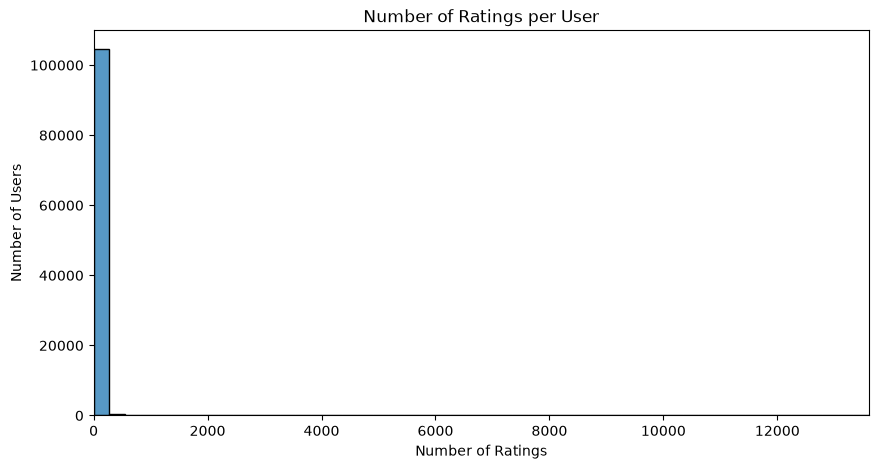

In [27]:
plt.figure(figsize=(10, 5))

sns.histplot(
    user_rating_counts,
    bins=50
)

plt.title("Number of Ratings per User")
plt.xlabel("Number of Ratings")
plt.ylabel("Number of Users")
plt.xlim(0, user_rating_counts.max())

plt.show()

In [28]:
# Count ratings received by each book

book_rating_counts = ratings.groupby('ISBN')['User-ID'].count()

print("Book Rating Statistics:")
print(book_rating_counts.describe())

print("\nBooks with only 1 rating:",
      (book_rating_counts == 1).sum())

print("Books with fewer than 10 ratings:",
      (book_rating_counts < 10).sum())

Book Rating Statistics:
count    340556.000000
mean          3.376185
std          12.436252
min           1.000000
25%           1.000000
50%           1.000000
75%           2.000000
max        2502.000000
Name: User-ID, dtype: float64

Books with only 1 rating: 197045
Books with fewer than 10 ratings: 322237


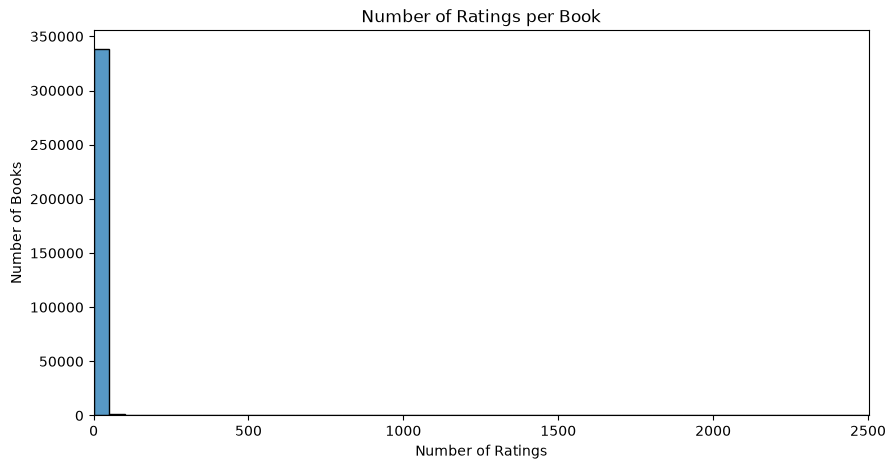

In [29]:
plt.figure(figsize=(10, 5))

sns.histplot(
    book_rating_counts,
    bins=50
)

plt.title("Number of Ratings per Book")
plt.xlabel("Number of Ratings")
plt.ylabel("Number of Books")
plt.xlim(0, book_rating_counts.max())

plt.show()

In [30]:
# Unique users and books appearing in ratings

total_users = ratings['User-ID'].nunique()
total_books = ratings['ISBN'].nunique()

# Total possible user-book combinations
total_possible_ratings = total_users * total_books

# Actual rating records
actual_ratings = len(ratings)

# Calculate sparsity
sparsity = (
    1 - actual_ratings / total_possible_ratings
) * 100

print("Total Unique Users:", total_users)
print("Total Unique Books:", total_books)
print("Actual Ratings:", actual_ratings)
print("Possible User-Book Pairs:", total_possible_ratings)

print(f"\nMatrix Sparsity: {sparsity:.4f}%")
print(f"Matrix Density: {100-sparsity:.4f}%")

Total Unique Users: 105283
Total Unique Books: 340556
Actual Ratings: 1149780
Possible User-Book Pairs: 35854757348

Matrix Sparsity: 99.9968%
Matrix Density: 0.0032%


In [32]:
# Ratings per user
user_rating_counts = ratings.groupby('User-ID').size()

# Ratings per book
book_rating_counts = ratings.groupby('ISBN').size()

print("USER RATING STATISTICS")
print(user_rating_counts.describe())

print("\nBOOK RATING STATISTICS")
print(book_rating_counts.describe())

print("\nUsers with fewer than 10 ratings:",
      (user_rating_counts < 10).sum())

print("Books with fewer than 10 ratings:",
      (book_rating_counts < 10).sum())

USER RATING STATISTICS
count    105283.000000
mean         10.920851
std          90.562825
min           1.000000
25%           1.000000
50%           1.000000
75%           4.000000
max       13602.000000
dtype: float64

BOOK RATING STATISTICS
count    340556.000000
mean          3.376185
std          12.436252
min           1.000000
25%           1.000000
50%           1.000000
75%           2.000000
max        2502.000000
dtype: float64

Users with fewer than 10 ratings: 92186
Books with fewer than 10 ratings: 322237


In [33]:
# Check ratings whose users are missing from Users
unmatched_users = set(ratings['User-ID']) - set(users['User-ID'])

# Check ratings whose books are missing from Books
unmatched_books = set(ratings['ISBN']) - set(books['ISBN'])

print("Unmatched users:", len(unmatched_users))
print("Unmatched books:", len(unmatched_books))

Unmatched users: 0
Unmatched books: 70386


# **Silver Layer: Data Cleaning**Cleaning

In [34]:
import pandas as pd
import numpy as np
import os

# Load Bronze datasets
bronze_users = pd.read_parquet('bronze/users.parquet')
bronze_books = pd.read_parquet('bronze/books.parquet')
bronze_ratings = pd.read_parquet('bronze/ratings.parquet')

# Create separate working copies
silver_users = bronze_users.copy()
silver_books = bronze_books.copy()
silver_ratings = bronze_ratings.copy()

print("Bronze datasets loaded successfully!")
print("Silver working copies created!")

Bronze datasets loaded successfully!
Silver working copies created!


In [35]:
print("INITIAL SILVER DATA")

print("Users:", silver_users.shape)
print("Books:", silver_books.shape)
print("Ratings:", silver_ratings.shape)

INITIAL SILVER DATA
Users: (278858, 3)
Books: (271380, 8)
Ratings: (1149780, 3)


In [36]:
# Store original row counts
before_users = len(silver_users)
before_books = len(silver_books)
before_ratings = len(silver_ratings)

# Remove completely duplicate rows
silver_users = silver_users.drop_duplicates().copy()
silver_books = silver_books.drop_duplicates().copy()
silver_ratings = silver_ratings.drop_duplicates().copy()

# Calculate removed duplicates
print("DUPLICATE REMOVAL REPORT")
print("------------------------")

print("Users duplicates removed:", before_users - len(silver_users))
print("Books duplicates removed:", before_books - len(silver_books))
print("Ratings duplicates removed:", before_ratings - len(silver_ratings))

print("\nUpdated Dataset Shapes:")
print("Users:", silver_users.shape)
print("Books:", silver_books.shape)
print("Ratings:", silver_ratings.shape)

DUPLICATE REMOVAL REPORT
------------------------
Users duplicates removed: 0
Books duplicates removed: 0
Ratings duplicates removed: 0

Updated Dataset Shapes:
Users: (278858, 3)
Books: (271380, 8)
Ratings: (1149780, 3)


In [38]:
# Check rating distribution before cleaning

print("Rating distribution BEFORE cleaning:")
print(silver_ratings['Book-Rating'].value_counts().sort_index())

# Count zero ratings
zero_ratings = (silver_ratings['Book-Rating'] == 0).sum()

# Remove zero ratings and retain ratings from 1 to 10
silver_ratings = silver_ratings[
    silver_ratings['Book-Rating'].between(1, 10)
].copy()

# Check results
print("\nZero ratings removed:", zero_ratings)

print("\nRating distribution AFTER cleaning:")
print(silver_ratings['Book-Rating'].value_counts().sort_index())

print("\nUpdated Ratings Shape:", silver_ratings.shape)

Rating distribution BEFORE cleaning:
Book-Rating
0     716109
1       1770
2       2759
3       5996
4       8904
5      50974
6      36924
7      76457
8     103736
9      67541
10     78610
Name: count, dtype: int64

Zero ratings removed: 716109

Rating distribution AFTER cleaning:
Book-Rating
1       1770
2       2759
3       5996
4       8904
5      50974
6      36924
7      76457
8     103736
9      67541
10     78610
Name: count, dtype: int64

Updated Ratings Shape: (433671, 3)


In [39]:
print("Remaining zero ratings:",
      (silver_ratings['Book-Rating'] == 0).sum())

print("Invalid ratings:",
      (~silver_ratings['Book-Rating'].between(1, 10)).sum())

Remaining zero ratings: 0
Invalid ratings: 0


In [40]:
# Check Age data type
print("Age data type:", silver_users['Age'].dtype)

# Convert Age to numeric
silver_users['Age'] = pd.to_numeric(
    silver_users['Age'],
    errors='coerce'
)

# Check age statistics
print("\nAge Statistics BEFORE cleaning:")
print(silver_users['Age'].describe())

# Check missing values
print("\nMissing ages:", silver_users['Age'].isnull().sum())

# Check invalid ages
print("Ages below 5:", (silver_users['Age'] < 5).sum())
print("Ages above 100:", (silver_users['Age'] > 100).sum())

Age data type: float64

Age Statistics BEFORE cleaning:
count    168096.000000
mean         34.751434
std          14.428097
min           0.000000
25%          24.000000
50%          32.000000
75%          44.000000
max         244.000000
Name: Age, dtype: float64

Missing ages: 110762
Ages below 5: 882
Ages above 100: 366


In [41]:
# Replace unrealistic ages with NaN

silver_users.loc[
    (silver_users['Age'] < 5) |
    (silver_users['Age'] > 100),
    'Age'
] = np.nan

print("Invalid ages replaced with null successfully!")

Invalid ages replaced with null successfully!


In [42]:
# Calculate median age
median_age = silver_users['Age'].median()

print("Median Age:", median_age)

Median Age: 32.0


In [43]:
# Fill missing ages with median
silver_users['Age'] = silver_users['Age'].fillna(median_age)

print("Missing ages filled successfully!")

Missing ages filled successfully!


In [44]:
print("Age Statistics AFTER cleaning:")
print(silver_users['Age'].describe())

print("\nRemaining missing ages:",
      silver_users['Age'].isnull().sum())

print("Ages below 5:",
      (silver_users['Age'] < 5).sum())

print("Ages above 100:",
      (silver_users['Age'] > 100).sum())

Age Statistics AFTER cleaning:
count    278858.000000
mean         33.643385
std          10.630979
min           5.000000
25%          29.000000
50%          32.000000
75%          35.000000
max         100.000000
Name: Age, dtype: float64

Remaining missing ages: 0
Ages below 5: 0
Ages above 100: 0


In [45]:
# Display sample locations
print(silver_users['Location'].head(10))

# Check missing locations
print("\nMissing locations:",
      silver_users['Location'].isnull().sum())

0                    nyc, new york, usa
1             stockton, california, usa
2       moscow, yukon territory, russia
3             porto, v.n.gaia, portugal
4    farnborough, hants, united kingdom
5         santa monica, california, usa
6                   washington, dc, usa
7              timmins, ontario, canada
8            germantown, tennessee, usa
9            albacete, wisconsin, spain
Name: Location, dtype: str

Missing locations: 0


In [46]:
# Split Location into City, State and Country
location_parts = (
    silver_users['Location']
    .fillna('')
    .astype(str)
    .str.rsplit(',', n=2, expand=True)
)

# Ensure exactly three columns
location_parts = location_parts.reindex(columns=range(3))

# Assign new columns
silver_users[['City', 'State', 'Country']] = location_parts

# Remove extra spaces
for col in ['City', 'State', 'Country']:
    silver_users[col] = silver_users[col].str.strip()
    silver_users[col] = silver_users[col].replace('', np.nan)

print("Location successfully split!")

Location successfully split!


In [48]:
# Check data type
print("Data type:", silver_books['Year-Of-Publication'].dtype)

# Convert to numeric
silver_books['Year-Of-Publication'] = pd.to_numeric(
    silver_books['Year-Of-Publication'],
    errors='coerce'
)

# Check statistics
print(silver_books['Year-Of-Publication'].describe())

# Check invalid values
print("\nYear 0:",
      (silver_books['Year-Of-Publication'] == 0).sum())

print("Future years:",
      (silver_books['Year-Of-Publication'] > 2026).sum())

Data type: str
count    271379.000000
mean       1959.756050
std         258.011363
min           0.000000
25%        1989.000000
50%        1995.000000
75%        2000.000000
max        2050.000000
Name: Year-Of-Publication, dtype: float64

Year 0: 4619
Future years: 11


In [49]:
# Replace zero and future publication years with NaN
silver_books.loc[
    (silver_books['Year-Of-Publication'] == 0) |
    (silver_books['Year-Of-Publication'] > 2026),
    'Year-Of-Publication'
] = np.nan

print("Invalid publication years replaced with null!")

Invalid publication years replaced with null!


In [50]:
print("Remaining missing years:",
      silver_books['Year-Of-Publication'].isnull().sum())

print("Year 0:",
      (silver_books['Year-Of-Publication'] == 0).sum())

print("Future years:",
      (silver_books['Year-Of-Publication'] > 2026).sum())

print("\nCleaned publication year statistics:")
print(silver_books['Year-Of-Publication'].describe())

Remaining missing years: 4631
Year 0: 0
Future years: 0

Cleaned publication year statistics:
count    266749.000000
mean       1993.687894
std           8.321821
min        1376.000000
25%        1989.000000
50%        1996.000000
75%        2000.000000
max        2026.000000
Name: Year-Of-Publication, dtype: float64


In [51]:
# Text columns in Books dataset
book_text_columns = [
    'Book-Title',
    'Book-Author',
    'Publisher'
]

# Remove extra whitespace and standardize text
for col in book_text_columns:
    silver_books[col] = (
        silver_books[col]
        .astype('string')
        .str.strip()
    )

# Standardize ISBN formatting
silver_books['ISBN'] = (
    silver_books['ISBN']
    .astype('string')
    .str.strip()
)

print("Books text columns cleaned!")

Books text columns cleaned!


In [52]:
# Clean geographical columns
user_text_columns = ['City', 'State', 'Country']

for col in user_text_columns:
    silver_users[col] = (
        silver_users[col]
        .astype('string')
        .str.strip()
        .str.title()
    )

print("Users location columns cleaned!")

Users location columns cleaned!


In [53]:
# Identify image URL columns
image_columns = [
    'Image-URL-S',
    'Image-URL-M',
    'Image-URL-L'
]

# Remove image URL columns if present
silver_books = silver_books.drop(
    columns=image_columns,
    errors='ignore'
)

print("Image URL columns removed!")

Image URL columns removed!


In [54]:
# Clean ISBN values in both datasets
silver_books['ISBN'] = (
    silver_books['ISBN']
    .astype('string')
    .str.strip()
)

silver_ratings['ISBN'] = (
    silver_ratings['ISBN']
    .astype('string')
    .str.strip()
)

In [55]:
# Find users and books that do not exist in master datasets
unmatched_users = set(silver_ratings['User-ID']) - set(silver_users['User-ID'])

unmatched_books = set(silver_ratings['ISBN']) - set(silver_books['ISBN'])

print("Unmatched users:", len(unmatched_users))
print("Unmatched books:", len(unmatched_books))

print("\nRatings before filtering:", len(silver_ratings))

Unmatched users: 0
Unmatched books: 36130

Ratings before filtering: 433671


In [56]:
# Keep ratings only for existing users and books
silver_ratings = silver_ratings[
    silver_ratings['User-ID'].isin(silver_users['User-ID']) &
    silver_ratings['ISBN'].isin(silver_books['ISBN'])
].copy()

print("Ratings after filtering:", len(silver_ratings))
print("Removed ratings:",
      len(bronze_ratings) - len(silver_ratings))

Ratings after filtering: 383853
Removed ratings: 765927


In [57]:
# Verify all ratings have valid users and books
remaining_unmatched_users = (
    set(silver_ratings['User-ID']) -
    set(silver_users['User-ID'])
)

remaining_unmatched_books = (
    set(silver_ratings['ISBN']) -
    set(silver_books['ISBN'])
)

print("Remaining unmatched users:", len(remaining_unmatched_users))
print("Remaining unmatched books:", len(remaining_unmatched_books))

print("\nFinal Silver Shapes:")
print("Users:", silver_users.shape)
print("Books:", silver_books.shape)
print("Ratings:", silver_ratings.shape)

Remaining unmatched users: 0
Remaining unmatched books: 0

Final Silver Shapes:
Users: (278858, 6)
Books: (271380, 5)
Ratings: (383853, 3)


In [58]:
# Count ratings per user and book
user_rating_counts = silver_ratings.groupby('User-ID').size()
book_rating_counts = silver_ratings.groupby('ISBN').size()

print("Users with fewer than 10 ratings:",
      (user_rating_counts < 10).sum())

print("Users with at least 10 ratings:",
      (user_rating_counts >= 10).sum())

print("\nBooks with fewer than 10 ratings:",
      (book_rating_counts < 10).sum())

print("Books with at least 10 ratings:",
      (book_rating_counts >= 10).sum())

Users with fewer than 10 ratings: 61503
Users with at least 10 ratings: 6589

Books with fewer than 10 ratings: 144398
Books with at least 10 ratings: 5444


In [59]:
MIN_USER_RATINGS = 10
MIN_BOOK_RATINGS = 10

previous_shape = None

while previous_shape != silver_ratings.shape:
    previous_shape = silver_ratings.shape

    # Count ratings in the current dataset
    user_counts = silver_ratings.groupby('User-ID').size()
    book_counts = silver_ratings.groupby('ISBN').size()

    # Identify users and books meeting the threshold
    valid_users = user_counts[
        user_counts >= MIN_USER_RATINGS
    ].index

    valid_books = book_counts[
        book_counts >= MIN_BOOK_RATINGS
    ].index

    # Retain only qualifying users and books
    silver_ratings = silver_ratings[
        silver_ratings['User-ID'].isin(valid_users) &
        silver_ratings['ISBN'].isin(valid_books)
    ].copy()

# Update Users and Books datasets
silver_users = silver_users[
    silver_users['User-ID'].isin(silver_ratings['User-ID'])
].copy()

silver_books = silver_books[
    silver_books['ISBN'].isin(silver_ratings['ISBN'])
].copy()

print("Minimum rating threshold applied successfully!")

Minimum rating threshold applied successfully!


# **💾 Save Silver Layer as Parquet**

In [60]:
import os

# Create Silver folder if it doesn't exist
os.makedirs('silver', exist_ok=True)

print("Silver folder created successfully!")

Silver folder created successfully!


In [61]:
# Save Silver datasets as Parquet files

silver_users.to_parquet(
    'silver/users.parquet',
    index=False
)

silver_books.to_parquet(
    'silver/books.parquet',
    index=False
)

silver_ratings.to_parquet(
    'silver/ratings.parquet',
    index=False
)

print("All Silver datasets saved successfully!")

All Silver datasets saved successfully!


In [62]:
# Load saved Silver datasets
check_users = pd.read_parquet('silver/users.parquet')
check_books = pd.read_parquet('silver/books.parquet')
check_ratings = pd.read_parquet('silver/ratings.parquet')

print("Saved Silver Layer Shapes:")
print("Users:", check_users.shape)
print("Books:", check_books.shape)
print("Ratings:", check_ratings.shape)

Saved Silver Layer Shapes:
Users: (1820, 6)
Books: (2030, 5)
Ratings: (41456, 3)


In [63]:
print("Silver folder files:")

for file in os.listdir('silver'):
    print(file)

Silver folder files:
books.parquet
ratings.parquet
users.parquet


Gold Layer: Feature Engineering for Book Recommendations

In [64]:
# Load Silver Layer datasets

silver_users = pd.read_parquet('silver/users.parquet')
silver_books = pd.read_parquet('silver/books.parquet')
silver_ratings = pd.read_parquet('silver/ratings.parquet')

print("Silver datasets loaded successfully!")

print("\nUsers:", silver_users.shape)
print("Books:", silver_books.shape)
print("Ratings:", silver_ratings.shape)

Silver datasets loaded successfully!

Users: (1820, 6)
Books: (2030, 5)
Ratings: (41456, 3)


In [65]:
# Create Book Lookup Table

book_lookup = silver_books[
    ['ISBN', 'Book-Title', 'Book-Author']
].drop_duplicates(subset='ISBN').copy()

# Reset index
book_lookup = book_lookup.reset_index(drop=True)

print("Book Lookup Table created!")

print("\nShape:", book_lookup.shape)
print("\nSample records:")
display(book_lookup.head(10))

Book Lookup Table created!

Shape: (2030, 3)

Sample records:


,ISBN,Book-Title,Book-Author
0,0440234743,The Testament,John Grisham
1,0452264464,Beloved (Plume Contemporary Fiction),Toni Morrison
2,0971880107,Wild Animus,Rich Shapero
3,0345402871,Airframe,Michael Crichton
4,0345417623,Timeline,MICHAEL CRICHTON
5,0446310786,To Kill a Mockingbird,Harper Lee
6,0449005615,Seabiscuit: An American Legend,LAURA HILLENBRAND
7,0671888587,I'll Be Seeing You,Mary Higgins Clark
8,0553582747,From the Corner of His Eye,Dean Koontz
9,0425182908,Isle of Dogs,Patricia Cornwell


In [66]:
# Calculate user aggregates

user_aggregates = (
    silver_ratings
    .groupby('User-ID')
    .agg(
        Total_Ratings=('Book-Rating', 'count'),
        Average_Rating=('Book-Rating', 'mean')
    )
    .reset_index()
)

print("User Aggregates created!")

print("\nShape:", user_aggregates.shape)
display(user_aggregates.head(10))

User Aggregates created!

Shape: (1820, 3)


,User-ID,Total_Ratings,Average_Rating
0,243,13,7.769231
1,254,20,8.450000
2,638,22,9.454545
3,805,10,8.400000
4,882,17,8.235294
5,1131,14,6.857143
6,1424,11,7.181818
7,1435,13,6.615385
8,1733,11,7.181818
9,1848,10,8.600000


In [67]:
# Calculate book aggregates

book_aggregates = (
    silver_ratings
    .groupby('ISBN')
    .agg(
        Total_Ratings=('Book-Rating', 'count'),
        Average_Rating=('Book-Rating', 'mean')
    )
    .reset_index()
)

print("Book Aggregates created!")

print("\nShape:", book_aggregates.shape)
display(book_aggregates.head(10))

Book Aggregates created!

Shape: (2030, 3)


,ISBN,Total_Ratings,Average_Rating
0,0020199600,12,8.166667
1,0020442203,12,8.833333
2,002542730X,27,7.481481
3,0028604199,10,7.900000
4,0060002050,11,7.545455
5,006000438X,18,7.277778
6,0060008032,18,7.388889
7,006001203X,11,8.090909
8,0060085444,12,7.083333
9,0060085452,18,8.111111


In [68]:
from scipy.sparse import csr_matrix, save_npz

print("Sparse matrix libraries imported!")

Sparse matrix libraries imported!


In [69]:
# Create unique user and book lists

user_ids = silver_ratings['User-ID'].unique()
book_ids = silver_ratings['ISBN'].unique()

# Create mappings
user_to_index = {
    user_id: index
    for index, user_id in enumerate(user_ids)
}

book_to_index = {
    book_id: index
    for index, book_id in enumerate(book_ids)
}

print("Total users:", len(user_to_index))
print("Total books:", len(book_to_index))

Total users: 1820
Total books: 2030


In [70]:
# Convert IDs into numerical indexes

row_indices = silver_ratings['User-ID'].map(user_to_index)
col_indices = silver_ratings['ISBN'].map(book_to_index)

ratings_values = silver_ratings['Book-Rating'].values

# Create sparse User-Book matrix
user_book_matrix = csr_matrix(
    (
        ratings_values,
        (row_indices, col_indices)
    ),
    shape=(len(user_ids), len(book_ids))
)

print("Sparse User-Book Rating Matrix created!")

print("Matrix Shape:", user_book_matrix.shape)
print("Number of Ratings:", user_book_matrix.nnz)
print("Matrix Data Type:", type(user_book_matrix))

Sparse User-Book Rating Matrix created!
Matrix Shape: (1820, 2030)
Number of Ratings: 41456
Matrix Data Type: <class 'scipy.sparse._csr.csr_matrix'>


In [71]:
total_possible_entries = (
    user_book_matrix.shape[0] *
    user_book_matrix.shape[1]
)

sparsity = (
    1 - user_book_matrix.nnz / total_possible_entries
) * 100

print(f"Matrix Sparsity: {sparsity:.4f}%")
print(f"Matrix Density: {100 - sparsity:.4f}%")

Matrix Sparsity: 98.8779%
Matrix Density: 1.1221%


In [72]:
import os

os.makedirs('gold', exist_ok=True)

# Save lookup and aggregate tables
book_lookup.to_parquet('gold/book_lookup.parquet', index=False)

user_aggregates.to_parquet(
    'gold/user_aggregates.parquet',
    index=False
)

book_aggregates.to_parquet(
    'gold/book_aggregates.parquet',
    index=False
)

# Save sparse matrix
save_npz('gold/user_book_matrix.npz', user_book_matrix)

# Save ID mappings
pd.Series(user_ids).to_pickle('gold/user_ids.pkl')
pd.Series(book_ids).to_pickle('gold/book_ids.pkl')

print("Gold Layer datasets saved successfully!")

Gold Layer datasets saved successfully!


In [73]:
print("Gold folder contents:")

for file in os.listdir('gold'):
    print(file)

Gold folder contents:
book_aggregates.parquet
book_ids.pkl
book_lookup.parquet
user_aggregates.parquet
user_book_matrix.npz
user_ids.pkl


In [74]:
import pandas as pd
import numpy as np

from scipy.sparse import load_npz
from sklearn.neighbors import NearestNeighbors

# Load Gold datasets
book_lookup = pd.read_parquet('gold/book_lookup.parquet')
user_aggregates = pd.read_parquet('gold/user_aggregates.parquet')
book_aggregates = pd.read_parquet('gold/book_aggregates.parquet')

# Load sparse matrix
user_book_matrix = load_npz('gold/user_book_matrix.npz')

# Load ID mappings
user_ids = pd.read_pickle('gold/user_ids.pkl').to_numpy()
book_ids = pd.read_pickle('gold/book_ids.pkl').to_numpy()

print("Gold data loaded successfully!")

print("User-Book Matrix:", user_book_matrix.shape)
print("Users:", len(user_ids))
print("Books:", len(book_ids))

Gold data loaded successfully!
User-Book Matrix: (1820, 2030)
Users: 1820
Books: 2030


In [75]:
# Convert User-Book matrix into Book-User matrix

book_user_matrix = user_book_matrix.T.tocsr()

print("Book-User Matrix Shape:", book_user_matrix.shape)
print("Number of Ratings:", book_user_matrix.nnz)
print("Matrix Type:", type(book_user_matrix))

Book-User Matrix Shape: (2030, 1820)
Number of Ratings: 41456
Matrix Type: <class 'scipy.sparse._csr.csr_matrix'>


# **Train Book Similarity Model Using Cosine Similarity**